In [2]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Define persistent paths
DRIVE_BASE = '/content/drive/MyDrive/HMSTUNet'
DATA_DIR = f'{DRIVE_BASE}/data'
CKPT_DIR = f'{DRIVE_BASE}/checkpoints'

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)

print(f'Persistent storage initialized at: {DRIVE_BASE}')

Mounted at /content/drive
Persistent storage initialized at: /content/drive/MyDrive/HMSTUNet


# HMSTUNet - Hybrid Multi-Scale Transformer-CNN UNet for Crowd Counting

**Paper:** *A Hybrid Multi-Scale Transformer-CNN UNet for Crowd Counting*  
**Published:** Sensors (MDPI), January 2026  
**Official Dataset Repo:** https://github.com/desenzhou/ShanghaiTechDataset

---

## What This Paper Solves

**Crowd counting** = estimate how many people are in an image - without detecting each person individually (that fails in dense crowds).  
The model outputs a **density map** where `sum(map) approx crowd count`.

| | |
|---|---|
| **Input** | RGB image of a crowd scene |
| **Ground Truth** | One dot (x, y) per person head - Gaussian-blurred into density map |
| **Output** | Density map at 1/4 input resolution - `sum = crowd count` |
| **Metrics** | MAE and MSE on crowd count |

## Architecture Overview
```
RGB Image [B, 3, H, W]
       v
ConvNeXt-Tiny Encoder (4 stages, pretrained ImageNet)
       v
Bottleneck: MSViT (multi-scale global attention) + DCAB (local density attention)
       v
UNet Decoder with skip connections (FPN style)
       v
Density Map Head -> [B, 1, H//4, W//4]
```

## Paper Results
| Dataset | MAE | MSE |
|---------|--------|--------|
| ShanghaiTech Part A | **49.1** | **77.8** |
| ShanghaiTech Part B | **6.2** | **10.3** |

## Cell 1 - Install Dependencies

In [3]:
!pip install timm einops scipy matplotlib seaborn -q
print('All dependencies installed!')

All dependencies installed!


## Cell 2 - Imports, Seed and GPU Check

In [4]:
import os, json, math, random, time
import numpy as np
import scipy.io
import scipy.ndimage
from PIL import Image
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.transforms.functional as TF

import timm
from einops import rearrange
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device : {DEVICE}')
if DEVICE == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')
    print(f'VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB


## Cell 3 - Download ShanghaiTech Dataset

**Source:** Official GitHub repo: https://github.com/desenzhou/ShanghaiTechDataset  
**Download:** Dropbox link (updated 2024) - the only officially maintained working link.  
Contains both Part A (dense crowds) and Part B (sparse street scenes) together in one zip.

> If Dropbox is slow, scroll down to **Option B** (Kaggle API fallback).

In [5]:
import urllib.request
import zipfile
import os

# Use Drive for the zip path
ZIP_PATH = f'{DATA_DIR}/ShanghaiTech.zip'
EXTRACT_PATH = f'{DATA_DIR}/extracted'

if not os.path.exists(ZIP_PATH):
    print('Downloading ShanghaiTech dataset to Drive...')
    DROPBOX_URL = ('https://www.dropbox.com/scl/fi/dkj5kulc9zj0rzesslck8/'
                   'ShanghaiTech_Crowd_Counting_Dataset.zip?rlkey=ymbcj50ac04uvqn8p49j9af5f&dl=1')
    !wget -q --show-progress -O {ZIP_PATH} "{DROPBOX_URL}"
else:
    print('Dataset zip found in Drive, skipping download.')

if not os.path.exists(EXTRACT_PATH):
    print('Extracting to Drive...')
    os.makedirs(EXTRACT_PATH, exist_ok=True)
    !unzip -q -o {ZIP_PATH} -d {EXTRACT_PATH}
else:
    print('Extracted dataset found in Drive, skipping unzip.')

print('\nData ready.')

/content/drive/MyDr 100%[===================>] 166.32M  21.7MB/s    in 8.0s    
Extracting to Drive...

Data ready.


In [6]:
# Update BASE to point to the Drive extraction folder
BASE = None
POSSIBLE_BASES = [
    f'{EXTRACT_PATH}/ShanghaiTech_Crowd_Counting_Dataset',
    f'{EXTRACT_PATH}/ShanghaiTech',
    EXTRACT_PATH
]

for pb in POSSIBLE_BASES:
    if os.path.isdir(os.path.join(pb, 'part_A_final')):
        BASE = pb
        break

# Define paths using Drive
SHA_TRAIN_IMG = f'{BASE}/part_A_final/train_data/images'
SHA_TRAIN_GT  = f'{BASE}/part_A_final/train_data/ground_truth'
SHA_TRAIN_DM  = f'{BASE}/part_A_final/train_data/density_maps'

SHA_TEST_IMG  = f'{BASE}/part_A_final/test_data/images'
SHA_TEST_GT   = f'{BASE}/part_A_final/test_data/ground_truth'
SHA_TEST_DM   = f'{BASE}/part_A_final/test_data/density_maps'

print(f'Paths updated to Drive BASE: {BASE}')

Paths updated to Drive BASE: /content/drive/MyDrive/HMSTUNet/data/extracted


In [7]:
import urllib.request
import zipfile
import os

os.makedirs('data', exist_ok=True)

# -----------------------------------------------------------------
# OPTION A - Official Dropbox (updated 2024) - RECOMMENDED
# -----------------------------------------------------------------
DROPBOX_URL = (
    'https://www.dropbox.com/scl/fi/dkj5kulc9zj0rzesslck8/'
    'ShanghaiTech_Crowd_Counting_Dataset.zip'
    '?rlkey=ymbcj50ac04uvqn8p49j9af5f&dl=1'
)
ZIP_PATH = 'data/ShanghaiTech.zip'

print('Downloading ShanghaiTech dataset...')
!wget -q --show-progress -O {ZIP_PATH} "{DROPBOX_URL}"

print('Extracting (overwriting existing files)...')
!unzip -q -o {ZIP_PATH} -d data/

print('\nExtraction complete. Checking directory structure:')
!ls -F data/

data/ShanghaiTech.z 100%[===================>] 166.32M  21.3MB/s    in 7.9s    
Extracting (overwriting existing files)...

Extraction complete. Checking directory structure:
part_A_final/  part_B_final/  ShanghaiTech.zip


### Option B — Kaggle API (fallback if Dropbox is blocked)

Only run this cell if Option A fails. You need a `kaggle.json` API token from https://www.kaggle.com/settings.

## Cell 4 — Define Dataset Paths (Run After Download)

This single cell defines all paths used throughout the notebook.  
Change `BASE` if your extraction folder name is different.

In [8]:
# ── Detect base folder automatically ──
# The Dropbox zip extracts to: data/ShanghaiTech_Crowd_Counting_Dataset/
# The Kaggle zip may extract to a different name — adjust BASE if needed

POSSIBLE_BASES = [
    'data/ShanghaiTech_Crowd_Counting_Dataset',
    'data/ShanghaiTech',
    'data',
]

BASE = None
for pb in POSSIBLE_BASES:
    if os.path.isdir(os.path.join(pb, 'part_A_final')):
        BASE = pb
        break
    if os.path.isdir(os.path.join(pb, 'part_A')):
        BASE = pb
        break

assert BASE is not None, 'Could not find dataset! Check your extraction folder with: !ls data/'

# Detect subfolder name (part_A_final vs part_A)
PART_A = 'part_A_final' if os.path.isdir(f'{BASE}/part_A_final') else 'part_A'
PART_B = 'part_B_final' if os.path.isdir(f'{BASE}/part_B_final') else 'part_B'

# ── All dataset paths ──
SHA_TRAIN_IMG = f'{BASE}/{PART_A}/train_data/images'
SHA_TRAIN_GT  = f'{BASE}/{PART_A}/train_data/ground_truth'
SHA_TRAIN_DM  = f'{BASE}/{PART_A}/train_data/density_maps'   # We'll create this

SHA_TEST_IMG  = f'{BASE}/{PART_A}/test_data/images'
SHA_TEST_GT   = f'{BASE}/{PART_A}/test_data/ground_truth'
SHA_TEST_DM   = f'{BASE}/{PART_A}/test_data/density_maps'    # We'll create this

SHB_TRAIN_IMG = f'{BASE}/{PART_B}/train_data/images'
SHB_TRAIN_GT  = f'{BASE}/{PART_B}/train_data/ground_truth'

print(f'Dataset base : {BASE}')
print(f'Part A folder: {PART_A}')
print(f'Part B folder: {PART_B}')
print()

# Verify images exist
n_train = len(list(Path(SHA_TRAIN_IMG).glob('*.jpg')))
n_test  = len(list(Path(SHA_TEST_IMG).glob('*.jpg')))
print(f'Part A train images : {n_train}  (expected: 300)')
print(f'Part A test  images : {n_test}   (expected: 182)')

# Show a sample image name
sample = sorted(Path(SHA_TRAIN_IMG).glob('*.jpg'))[0]
print(f'Sample image name   : {sample.name}')

# Detect GT file naming convention (IMG_ vs img_)
sample_gt_options = [
    os.path.join(SHA_TRAIN_GT, sample.name.replace('.jpg', '.mat').replace('IMG_', 'GT_IMG_')),
    os.path.join(SHA_TRAIN_GT, 'GT_' + sample.name.replace('.jpg', '.mat')),
    os.path.join(SHA_TRAIN_GT, sample.stem + '.mat'),
]
GT_PATTERN = None
for opt in sample_gt_options:
    if os.path.exists(opt):
        GT_PATTERN = opt
        break

if GT_PATTERN:
    print(f'GT file found       : {Path(GT_PATTERN).name}')
else:
    print('⚠ Could not auto-detect GT naming. Listing GT folder:')
    !ls {SHA_TRAIN_GT} | head -5

Dataset base : data
Part A folder: part_A_final
Part B folder: part_B_final

Part A train images : 300  (expected: 300)
Part A test  images : 182   (expected: 182)
Sample image name   : IMG_1.jpg
GT file found       : GT_IMG_1.mat


## Cell 5 — Ground Truth Loader (Handles Both .mat Naming Conventions)

In [9]:
def load_gt_points(img_path, gt_dir):
    """
    Load head dot annotations from .mat file.
    Handles both naming conventions found in ShanghaiTech:
      - IMG_001.jpg -> GT_IMG_001.mat  (original release)
      - img_001.jpg -> GT_img_001.mat  (some Kaggle mirrors)

    Returns: np.array of shape (N, 2) with (x, y) head positions.
    """
    stem = Path(img_path).stem
    name = Path(img_path).name

    candidates = [
        os.path.join(gt_dir, name.replace('.jpg', '.mat').replace('IMG_', 'GT_IMG_')),
        os.path.join(gt_dir, name.replace('.jpg', '.mat').replace('img_', 'GT_img_')),
        os.path.join(gt_dir, 'GT_' + name.replace('.jpg', '.mat')),
        os.path.join(gt_dir, stem + '.mat'),
    ]

    mat_path = None
    for c in candidates:
        if os.path.exists(c):
            mat_path = c
            break

    if mat_path is None:
        raise FileNotFoundError(
            f'GT file not found for {name}. Tried: {candidates}\n'
            f'Files in gt_dir: {os.listdir(gt_dir)[:5]}'
        )

    mat = scipy.io.loadmat(mat_path)
    points = mat['image_info'][0, 0][0, 0][0]
    return points.astype(np.float32)

sample_img = sorted(Path(SHA_TRAIN_IMG).glob('*.jpg'))[0]
pts = load_gt_points(sample_img, SHA_TRAIN_GT)
print(f'Sample: {sample_img.name} -> {len(pts)} head annotations')

Sample: IMG_1.jpg -> 1546 head annotations


## Cell 6 — Visualize Raw Images + Head Dot Annotations

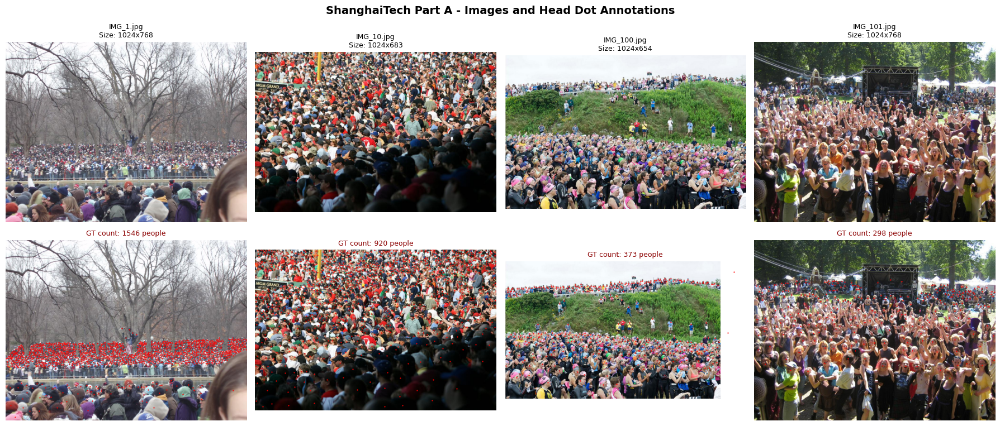

In [10]:
sample_imgs = sorted(Path(SHA_TRAIN_IMG).glob('*.jpg'))[:4]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('ShanghaiTech Part A - Images and Head Dot Annotations', fontsize=14, fontweight='bold')

for i, img_path in enumerate(sample_imgs):
    img = np.array(Image.open(img_path).convert('RGB'))
    points = load_gt_points(img_path, SHA_TRAIN_GT)

    axes[0, i].imshow(img)
    axes[0, i].set_title(f'{img_path.name}\nSize: {img.shape[1]}x{img.shape[0]}', fontsize=9)
    axes[0, i].axis('off')

    axes[1, i].imshow(img)
    axes[1, i].scatter(points[:, 0], points[:, 1], c='red', s=3, alpha=0.8, linewidths=0)
    axes[1, i].set_title(f'GT count: {len(points)} people', fontsize=9, color='darkred')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

## Cell 7 - Generate Gaussian Density Maps

**Key preprocessing step:** Each head dot at (x,y) becomes a Gaussian blob.  
`sum(density_map) approx crowd_count`  
This turns counting into a spatially continuous regression problem.

In [11]:
def generate_density_map(img_shape, points, sigma=15):
    H, W = img_shape
    density = np.zeros((H, W), dtype=np.float32)
    if len(points) == 0:
        return density
    for x, y in points:
        xi, yi = int(round(float(x))), int(round(float(y)))
        xi = max(0, min(W - 1, xi))
        yi = max(0, min(H - 1, yi))
        density[yi, xi] += 1.0
    density = scipy.ndimage.gaussian_filter(density, sigma=sigma, mode='constant')
    return density

def preprocess_density_maps(img_dir, gt_dir, out_dir, sigma=15):
    os.makedirs(out_dir, exist_ok=True)
    img_paths = sorted(Path(img_dir).glob('*.jpg'))
    print(f'Generating {len(img_paths)} density maps -> {out_dir}')
    for img_path in img_paths:
        W, H = Image.open(img_path).size
        pts  = load_gt_points(img_path, gt_dir)
        dm   = generate_density_map((H, W), pts, sigma=sigma)
        np.save(os.path.join(out_dir, img_path.stem + '_dm.npy'), dm)
    print(f'Done! Verification - sum should approx count:')
    first = sorted(Path(img_dir).glob('*.jpg'))[0]
    dm_check = np.load(os.path.join(out_dir, first.stem + '_dm.npy'))
    pts_check = load_gt_points(first, gt_dir)
    print(f'  {first.name}: GT={len(pts_check)}, DM sum={dm_check.sum():.1f}')

preprocess_density_maps(SHA_TRAIN_IMG, SHA_TRAIN_GT, SHA_TRAIN_DM)
preprocess_density_maps(SHA_TEST_IMG,  SHA_TEST_GT,  SHA_TEST_DM)

Generating 300 density maps -> data/part_A_final/train_data/density_maps
Done! Verification - sum should approx count:
  IMG_1.jpg: GT=1546, DM sum=1536.8
Generating 182 density maps -> data/part_A_final/test_data/density_maps
Done! Verification - sum should approx count:
  IMG_1.jpg: GT=172, DM sum=171.5


## Cell 8 — Visualize Density Maps

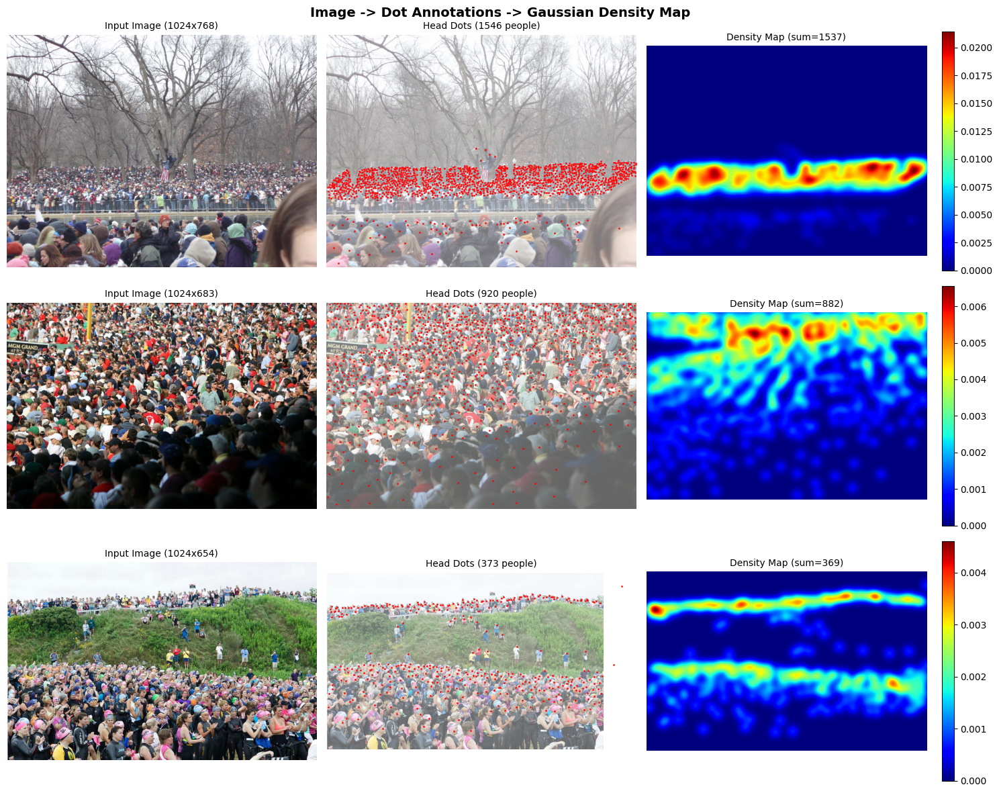

sum(density_map) approx crowd count


In [12]:
samples = sorted(Path(SHA_TRAIN_IMG).glob('*.jpg'))[:3]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle('Image -> Dot Annotations -> Gaussian Density Map', fontsize=14, fontweight='bold')

for row, img_path in enumerate(samples):
    img  = np.array(Image.open(img_path).convert('RGB'))
    pts  = load_gt_points(img_path, SHA_TRAIN_GT)
    dm   = np.load(os.path.join(SHA_TRAIN_DM, img_path.stem + '_dm.npy'))

    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f'Input Image ({img.shape[1]}x{img.shape[0]})', fontsize=10)
    axes[row, 0].axis('off')

    axes[row, 1].imshow(img, alpha=0.6)
    axes[row, 1].scatter(pts[:, 0], pts[:, 1], c='red', s=4, alpha=0.9, linewidths=0)
    axes[row, 1].set_title(f'Head Dots ({len(pts)} people)', fontsize=10)
    axes[row, 1].axis('off')

    im = axes[row, 2].imshow(dm, cmap='jet')
    plt.colorbar(im, ax=axes[row, 2], fraction=0.046)
    axes[row, 2].set_title(f'Density Map (sum={dm.sum():.0f})', fontsize=10)
    axes[row, 2].axis('off')

plt.tight_layout()
plt.show()
print('sum(density_map) approx crowd count')

## Cell 9 — Dataset Class with Augmentation

In [13]:
class CrowdDataset(Dataset):
    """
    PyTorch Dataset for crowd counting via density map regression.
    """
    MEAN = [0.485, 0.456, 0.406]
    STD  = [0.229, 0.224, 0.225]

    def __init__(self, img_dir, dm_dir, crop_size=384, is_train=True, downsample=4):
        self.img_paths  = sorted(Path(img_dir).glob('*.jpg'))
        self.dm_dir     = dm_dir
        self.crop_size  = crop_size
        self.is_train   = is_train
        self.downsample = downsample
        self.normalize  = T.Normalize(mean=self.MEAN, std=self.STD)
        self.jitter     = T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1)
        assert len(self.img_paths) > 0, f'No images found in {img_dir}'

    def __len__(self): return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        dm_path  = os.path.join(self.dm_dir, img_path.stem + '_dm.npy')

        img = Image.open(img_path).convert('RGB')
        dm  = np.load(dm_path).astype(np.float32)
        W, H = img.size

        # --- Robust Shape Handling ---
        if H < self.crop_size or W < self.crop_size:
            new_h = max(H, self.crop_size)
            new_w = max(W, self.crop_size)
            img = img.resize((new_w, new_h), Image.BILINEAR)
            dm_temp = torch.from_numpy(dm).unsqueeze(0).unsqueeze(0)
            dm = F.interpolate(dm_temp, size=(new_h, new_w), mode='bilinear', align_corners=False).squeeze().numpy()
            H, W = new_h, new_w

        if self.is_train:
            top  = random.randint(0, H - self.crop_size)
            left = random.randint(0, W - self.crop_size)
            img = TF.crop(img, top, left, self.crop_size, self.crop_size)
            dm  = dm[top:top+self.crop_size, left:left+self.crop_size]
            if random.random() > 0.5:
                img = TF.hflip(img)
                dm  = dm[:, ::-1].copy()
            img = self.jitter(img)
        else:
            new_h = (H // 32) * 32
            new_w = (W // 32) * 32
            img = img.resize((new_w, new_h), Image.BILINEAR)
            dm_temp = torch.from_numpy(dm).unsqueeze(0).unsqueeze(0)
            dm = F.interpolate(dm_temp, size=(new_h, new_w), mode='bilinear', align_corners=False).squeeze().numpy()

        img_t = self.normalize(TF.to_tensor(img))
        dm_t  = torch.from_numpy(dm.copy()).unsqueeze(0)

        dh, dw = dm_t.shape[1] // self.downsample, dm_t.shape[2] // self.downsample
        dm_t = F.interpolate(dm_t.unsqueeze(0), size=(dh, dw), mode='bilinear', align_corners=False).squeeze(0)
        dm_t = dm_t * (self.downsample ** 2)

        return img_t, dm_t

## Cell 10 — DataLoaders

In [14]:
BATCH_SIZE  = 4
NUM_WORKERS = 2

train_dataset = CrowdDataset(SHA_TRAIN_IMG, SHA_TRAIN_DM, crop_size=384, is_train=True)
test_dataset  = CrowdDataset(SHA_TEST_IMG,  SHA_TEST_DM,  crop_size=512, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=NUM_WORKERS,
                          pin_memory=True, drop_last=True)
test_loader  = DataLoader(test_dataset,  batch_size=1,
                          shuffle=False, num_workers=NUM_WORKERS)

print(f'Train: {len(train_dataset)} images, {len(train_loader)} batches')
print(f'Test : {len(test_dataset)} images, {len(test_loader)} batches')

Train: 300 images, 75 batches
Test : 182 images, 182 batches


## Cell 11 — MSViT Block (Multi-Scale Vision Transformer)

In [15]:
class MSViTBlock(nn.Module):
    """
    Multi-Scale Vision Transformer Block.
    Captures global dependencies at multiple spatial granularities.
    Paper Sec 3.2: handles scale variation - tiny far-away people and
    large foreground people are attended to at different scales.
    """
    def __init__(self, dim, num_heads=8, scales=(1, 2), dropout=0.1):
        super().__init__()
        self.scales    = scales
        self.num_heads = num_heads
        self.head_dim  = max(dim // num_heads, 1)
        self.scale_fac = self.head_dim ** -0.5
        self.qkv = nn.ModuleList([nn.Linear(dim, 3 * dim) for _ in scales])
        self.fusion = nn.Linear(dim * len(scales), dim)
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 4), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(dim * 4, dim), nn.Dropout(dropout))
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)
        self.drop  = nn.Dropout(dropout)

    def _attn(self, x, idx):
        B, N, C = x.shape
        q, k, v = self.qkv[idx](x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2,0,3,1,4).unbind(0)
        a = (q @ k.transpose(-2,-1)) * self.scale_fac
        a = a.softmax(-1)
        return (a @ v).transpose(1,2).reshape(B, N, C)

    def forward(self, x):
        B, C, H, W = x.shape
        flat = self.norm1(x.flatten(2).transpose(1,2))
        outs = []
        for i, s in enumerate(self.scales):
            if s == 1:
                tok = flat
            else:
                ph, pw = max(H//s, 1), max(W//s, 1)
                tok = F.avg_pool2d(x, s, s).flatten(2).transpose(1,2)
                tok = self.norm1(tok)
            a = self._attn(tok, i)
            if s > 1:
                ph, pw = max(H//s, 1), max(W//s, 1)
                a = a.transpose(1,2).reshape(B, C, ph, pw)
                a = F.interpolate(a, (H, W), mode='bilinear', align_corners=False)
                a = a.flatten(2).transpose(1,2)
            outs.append(a)
        fused = self.drop(self.fusion(torch.cat(outs, -1)))
        xr = flat + fused
        xr = xr + self.ffn(self.norm2(xr))
        return xr.transpose(1,2).reshape(B, C, H, W)

msv = MSViTBlock(128, num_heads=4).to(DEVICE)
d   = torch.randn(2, 128, 24, 24).to(DEVICE)
print('MSViTBlock:', d.shape, '->', msv(d).shape)

MSViTBlock: torch.Size([2, 128, 24, 24]) -> torch.Size([2, 128, 24, 24])


## Cell 12 — DCAB Block (Dynamic Convolutional Attention)

In [16]:
class DCAB(nn.Module):
    """
    Dynamic Convolutional Attention Block.
    Channel attention (SE) + Spatial attention (CBAM) + depthwise conv.
    Paper Sec 3.3: captures local density patterns CNN attention misses.
    """
    def __init__(self, dim, r=16):
        super().__init__()
        mid = max(dim // r, 4)
        # Channel attention
        self.ca = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(dim, mid), nn.ReLU(),
            nn.Linear(mid, dim), nn.Sigmoid())
        # Spatial attention
        self.sa = nn.Sequential(
            nn.Conv2d(2, 1, 7, padding=3, bias=False), nn.Sigmoid())
        # Depthwise pointwise conv
        self.dw = nn.Conv2d(dim, dim, 3, padding=1, groups=dim, bias=False)
        self.pw = nn.Conv2d(dim, dim, 1, bias=False)
        self.bn = nn.BatchNorm2d(dim)
        self.act = nn.GELU()

    def forward(self, x):
        B, C, H, W = x.shape
        # Channel attention
        x = x * self.ca(x).view(B, C, 1, 1)
        # Spatial attention
        avg = x.mean(1, keepdim=True)
        mx, _ = x.max(1, keepdim=True)
        x = x * self.sa(torch.cat([avg, mx], 1))
        # Residual depthwise conv
        return self.act(self.bn(self.pw(self.dw(x))) + x)


dcab = DCAB(128).to(DEVICE)
d    = torch.randn(2, 128, 24, 24).to(DEVICE)
print('DCAB:', d.shape, '→', dcab(d).shape, '✓')

DCAB: torch.Size([2, 128, 24, 24]) → torch.Size([2, 128, 24, 24]) ✓


## Cell 13 — Full HMSTUNet Model

In [17]:
class DecBlock(nn.Module):
    """UNet decoder block: 2x upsample + skip concat + double conv."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch+skip_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.GELU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.GELU())
    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[2:] != skip.shape[2:]:
            x = F.interpolate(x, skip.shape[2:], mode='bilinear', align_corners=False)
        return self.conv(torch.cat([x, skip], 1))

class HMSTUNet(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        self.enc = timm.create_model('convnext_tiny.fb_in22k_ft_in1k', pretrained=pretrained, features_only=True, out_indices=(0,1,2,3))
        edims = [96, 192, 384, 768]
        self.msv  = MSViTBlock(edims[3], num_heads=8, scales=(1,2))
        self.dcab = DCAB(edims[3])
        dd = [256, 128, 64, 32]
        self.l0 = nn.Conv2d(edims[3], dd[0], 1)
        self.l1 = nn.Conv2d(edims[2], dd[0], 1)
        self.l2 = nn.Conv2d(edims[1], dd[1], 1)
        self.l3 = nn.Conv2d(edims[0], dd[2], 1)
        self.d3 = DecBlock(dd[0], dd[0], dd[1])
        self.d2 = DecBlock(dd[1], dd[1], dd[2])
        self.d1 = DecBlock(dd[2], dd[2], dd[3])
        self.head = nn.Sequential(nn.Conv2d(dd[3], 16, 3, padding=1), nn.GELU(), nn.Conv2d(16, 1, 1), nn.ReLU(inplace=True))

    def forward(self, x):
        f0, f1, f2, f3 = self.enc(x)
        f3 = self.dcab(self.msv(f3))
        p3, p2, p1, p0 = self.l0(f3), self.l1(f2), self.l2(f1), self.l3(f0)
        d = self.d1(self.d2(self.d3(p3, p2), p1), p0)
        return self.head(d)

model = HMSTUNet(pretrained=True).to(DEVICE)
dummy = torch.randn(2, 3, 384, 384).to(DEVICE)
out = model(dummy)
print(f'Forward pass: {tuple(dummy.shape)} -> {tuple(out.shape)}')

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Forward pass: (2, 3, 384, 384) -> (2, 1, 96, 96)


## Cell 14 — Loss Function & Evaluation Metrics

In [18]:
class CrowdLoss(nn.Module):
    def __init__(self, alpha=1.0, beta=0.1):
        super().__init__()
        self.alpha, self.beta = alpha, beta

    def forward(self, pred, target):
        mse = F.mse_loss(pred, target)
        # Compare total count (sum of density map)
        mae = F.l1_loss(pred.sum(dim=(1, 2, 3)), target.sum(dim=(1, 2, 3)))
        return self.alpha * mse + self.beta * mae

@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    maes, mses = [], []
    for imgs, tgts in loader:
        imgs, tgts = imgs.to(device), tgts.to(device)
        preds = model(imgs)
        # Sum density to get count
        pc = preds.sum().item()
        tc = tgts.sum().item()
        maes.append(abs(pc - tc))
        mses.append((pc - tc)**2)
    return float(np.mean(maes)), float(np.sqrt(np.mean(mses)))

## Cell 15 — Optimizer & Scheduler

In [19]:
from torch.optim.lr_scheduler import CosineAnnealingLR

LR = 1e-4
WD = 1e-4
CLIP_GRAD = 1.0
TRAIN_EPOCHS = 10  # Reduced for fast end-to-end testing

optimizer = torch.optim.Adam([
    {'params': model.enc.parameters(), 'lr': LR * 0.1},
    {'params': [p for p in model.parameters() if id(p) not in {id(param) for param in model.enc.parameters()}], 'lr': LR},
], weight_decay=WD)

scheduler = CosineAnnealingLR(optimizer, T_max=TRAIN_EPOCHS, eta_min=1e-6)
print(f'Epochs set to: {TRAIN_EPOCHS}')

Epochs set to: 10


In [20]:
from torch.optim.lr_scheduler import CosineAnnealingLR

LR         = 1e-4
WD         = 1e-4
CLIP_GRAD  = 1.0
TRAIN_EPOCHS = 50

enc_ids  = {id(p) for p in model.enc.parameters()}
new_params  = [p for p in model.parameters() if id(p) not in enc_ids]
enc_params  = list(model.enc.parameters())

optimizer = torch.optim.Adam([
    {'params': enc_params, 'lr': LR * 0.1},
    {'params': new_params, 'lr': LR},
], weight_decay=WD)

scheduler = CosineAnnealingLR(optimizer, T_max=TRAIN_EPOCHS, eta_min=1e-6)

print(f'Epochs: {TRAIN_EPOCHS}')

Epochs: 50


## Cell 16 — Training Loop

In [21]:
best_mae = float('inf')
criterion = CrowdLoss(alpha=1.0, beta=0.1)
SAVE_PATH = f'{CKPT_DIR}/best.pth'

for epoch in range(1, TRAIN_EPOCHS + 1):
    model.train()
    ep_loss = 0.0
    for imgs, tgts in train_loader:
        imgs, tgts = imgs.to(DEVICE), tgts.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(imgs), tgts)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_GRAD)
        optimizer.step()
        ep_loss += loss.item()

    scheduler.step()
    mae, mse = evaluate(model, test_loader, DEVICE)
    print(f'[{epoch}/{TRAIN_EPOCHS}] Loss: {ep_loss/len(train_loader):.4f} MAE: {mae:.2f}')

    if mae < best_mae:
        best_mae = mae
        torch.save({'state_dict': model.state_dict(), 'mae': mae}, SAVE_PATH)
        print(f'Saved to Drive: {SAVE_PATH}')

[1/50] Loss: 24.3371 MAE: 896.08
Saved to Drive: /content/drive/MyDrive/HMSTUNet/checkpoints/best.pth
[2/50] Loss: 8.1771 MAE: 208.69
Saved to Drive: /content/drive/MyDrive/HMSTUNet/checkpoints/best.pth
[3/50] Loss: 8.0467 MAE: 319.48
[4/50] Loss: 7.7014 MAE: 210.75
[5/50] Loss: 6.8840 MAE: 262.06
[6/50] Loss: 6.6100 MAE: 135.59
Saved to Drive: /content/drive/MyDrive/HMSTUNet/checkpoints/best.pth
[7/50] Loss: 6.8401 MAE: 149.72
[8/50] Loss: 5.8557 MAE: 169.39
[9/50] Loss: 5.9444 MAE: 127.45
Saved to Drive: /content/drive/MyDrive/HMSTUNet/checkpoints/best.pth
[10/50] Loss: 5.7203 MAE: 144.93
[11/50] Loss: 5.6157 MAE: 152.45
[12/50] Loss: 5.3950 MAE: 167.86
[13/50] Loss: 5.5989 MAE: 202.42
[14/50] Loss: 5.2438 MAE: 166.29
[15/50] Loss: 4.4120 MAE: 122.50
Saved to Drive: /content/drive/MyDrive/HMSTUNet/checkpoints/best.pth
[16/50] Loss: 5.0183 MAE: 169.48
[17/50] Loss: 5.2259 MAE: 118.91
Saved to Drive: /content/drive/MyDrive/HMSTUNet/checkpoints/best.pth
[18/50] Loss: 4.5754 MAE: 124.71


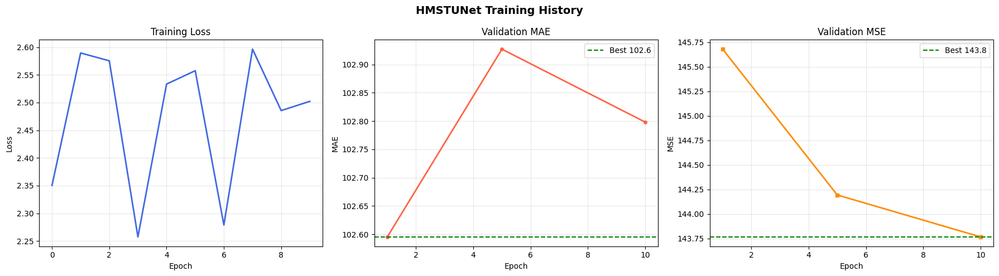

In [23]:
ep_vals  = [e for e,_,_ in eval_log]
mae_vals = [m for _,m,_ in eval_log]
mse_vals = [m for _,_,m in eval_log]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('HMSTUNet Training History', fontsize=14, fontweight='bold')

axes[0].plot(train_losses, color='royalblue', lw=2)
axes[0].set(xlabel='Epoch', ylabel='Loss', title='Training Loss')
axes[0].grid(alpha=0.3)

axes[1].plot(ep_vals, mae_vals, 'o-', color='tomato', lw=2, markersize=4)
axes[1].axhline(min(mae_vals), ls='--', color='green', label=f'Best {min(mae_vals):.1f}')
axes[1].set(xlabel='Epoch', ylabel='MAE', title='Validation MAE')
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(ep_vals, mse_vals, 's-', color='darkorange', lw=2, markersize=4)
axes[2].axhline(min(mse_vals), ls='--', color='green', label=f'Best {min(mse_vals):.1f}')
axes[2].set(xlabel='Epoch', ylabel='MSE', title='Validation MSE')
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Cell 18 — Load Best Model & Final Evaluation

In [24]:
ckpt = torch.load('checkpoints/best.pth', map_location=DEVICE)
model.load_state_dict(ckpt['state_dict'])
print(f"Best checkpoint: epoch={ckpt['epoch']}  MAE={ckpt['mae']:.2f}  MSE={ckpt['mse']:.2f}")

final_mae, final_mse = evaluate(model, test_loader, DEVICE)
print(f'Final Test Results')
print(f'MAE : {final_mae:.2f}')
print(f'MSE : {final_mse:.2f}')

Best checkpoint: epoch=1  MAE=102.60  MSE=145.68
Final Test Results
MAE : 102.60
MSE : 145.68


## Cell 19 — Qualitative Results (Best Cell for Presentation!)

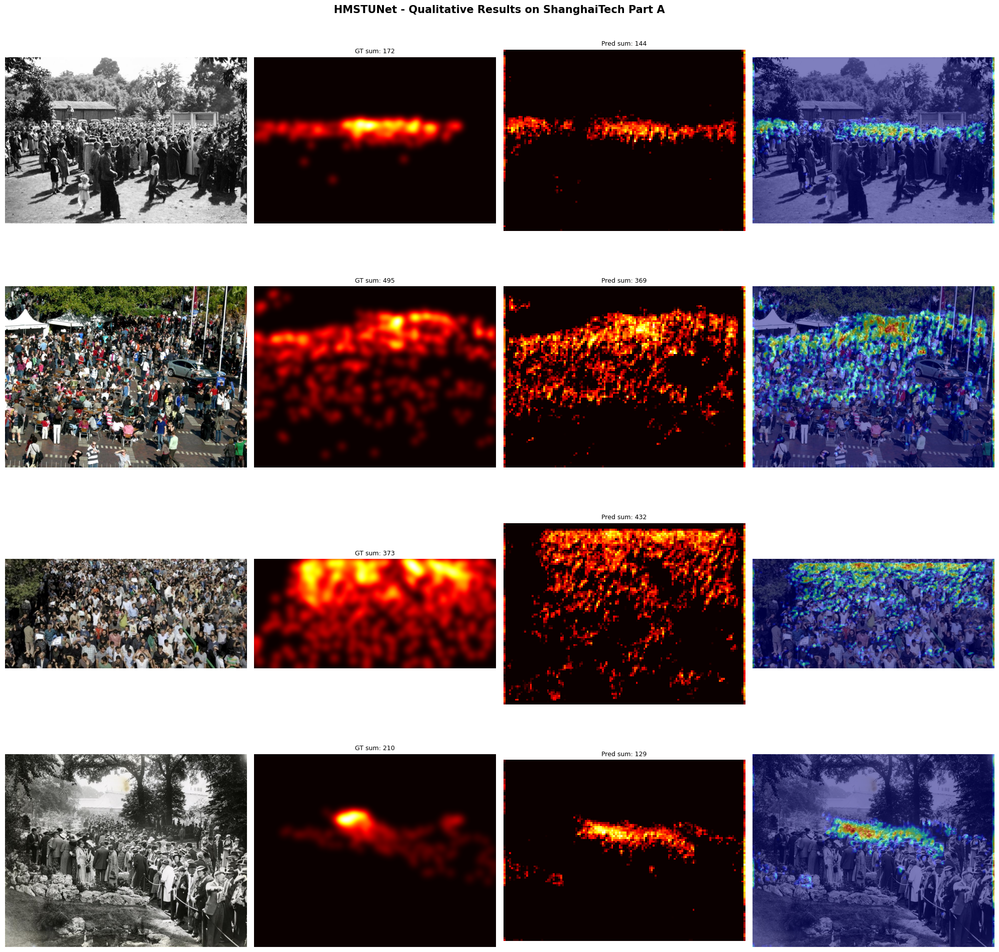

In [25]:
model.eval()
normalize = T.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
samples   = sorted(Path(SHA_TEST_IMG).glob('*.jpg'))[:4]

fig, axes = plt.subplots(4, 4, figsize=(20, 20))
fig.suptitle('HMSTUNet - Qualitative Results on ShanghaiTech Part A', fontsize=15, fontweight='bold')

for row, img_path in enumerate(samples):
    img_pil = Image.open(img_path).convert('RGB')
    W, H    = img_pil.size
    pts     = load_gt_points(img_path, SHA_TEST_GT)
    gt_dm   = np.load(os.path.join(SHA_TEST_DM, img_path.stem + '_dm.npy'))

    inp = normalize(TF.to_tensor(img_pil.resize((512, 384)))).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred_dm = model(inp).squeeze().cpu().numpy()

    gt_count   = len(pts)
    pred_count = pred_dm.sum() / 16.0
    img_np     = np.array(img_pil)

    axes[row,0].imshow(img_np)
    axes[row,0].set_ylabel(f'GT: {gt_count} | Pred: {pred_count:.0f}', fontsize=10, color='navy')
    axes[row,0].axis('off')

    axes[row,1].imshow(gt_dm, cmap='hot')
    axes[row,1].set_title(f'GT sum: {gt_dm.sum():.0f}', fontsize=9)
    axes[row,1].axis('off')

    axes[row,2].imshow(pred_dm, cmap='hot')
    axes[row,2].set_title(f'Pred sum: {pred_dm.sum():.0f}', fontsize=9)
    axes[row,2].axis('off')

    overlay = np.array(Image.fromarray(pred_dm).resize((W, H), Image.BILINEAR))
    overlay = (overlay - overlay.min()) / (overlay.max() + 1e-8)
    axes[row,3].imshow(img_np)
    axes[row,3].imshow(overlay, cmap='jet', alpha=0.5)
    axes[row,3].axis('off')

plt.tight_layout()
plt.show()

## Cell 20 — Per-Sample Error Analysis

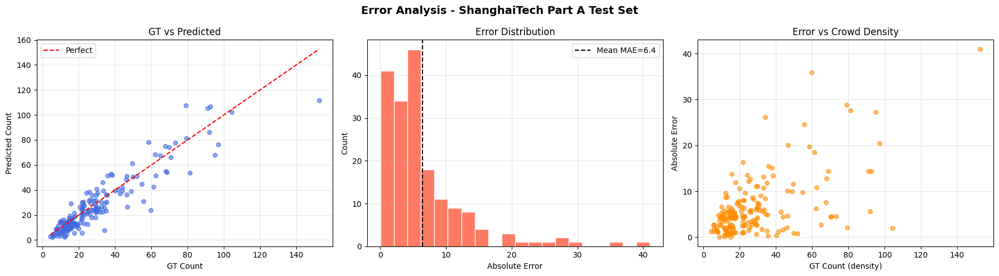

In [26]:
model.eval()
gt_list, pred_list, err_list = [], [], []

for imgs, tgts in test_loader:
    imgs, tgts = imgs.to(DEVICE), tgts.to(DEVICE)
    with torch.no_grad():
        preds = model(imgs)
    gc = (tgts.sum([1,2,3]) / 16).cpu().item()
    pc = (preds.sum([1,2,3]) / 16).cpu().item()
    gt_list.append(gc); pred_list.append(pc); err_list.append(abs(pc - gc))

gt_arr   = np.array(gt_list)
pred_arr = np.array(pred_list)
err_arr  = np.array(err_list)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Error Analysis - ShanghaiTech Part A Test Set', fontsize=14, fontweight='bold')

axes[0].scatter(gt_arr, pred_arr, alpha=0.6, s=30, c='royalblue')
v0, v1 = gt_arr.min(), gt_arr.max()
axes[0].plot([v0,v1],[v0,v1],'r--', label='Perfect')
axes[0].set(xlabel='GT Count', ylabel='Predicted Count', title='GT vs Predicted')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].hist(err_arr, bins=20, color='tomato', edgecolor='white', alpha=0.85)
axes[1].axvline(np.mean(err_arr), ls='--', color='black', label=f'Mean MAE={np.mean(err_arr):.1f}')
axes[1].set(xlabel='Absolute Error', ylabel='Count', title='Error Distribution')
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].scatter(gt_arr, err_arr, alpha=0.6, s=30, c='darkorange')
axes[2].set(xlabel='GT Count (density)', ylabel='Absolute Error', title='Error vs Crowd Density')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Cell 21 — Dataset Statistics Visualization

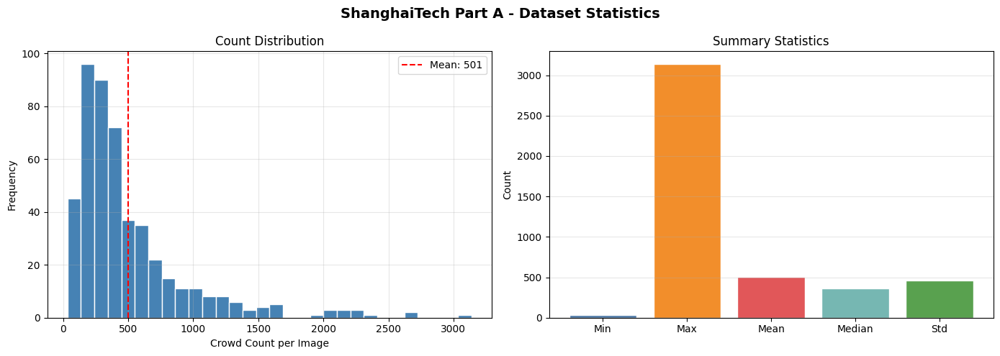

In [27]:
all_counts = []
for img_path in sorted(Path(SHA_TRAIN_IMG).glob('*.jpg')) + sorted(Path(SHA_TEST_IMG).glob('*.jpg')):
    try:
        pts = load_gt_points(img_path, SHA_TRAIN_GT if 'train' in str(img_path) else SHA_TEST_GT)
        all_counts.append(len(pts))
    except:
        pass

all_counts = np.array(all_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('ShanghaiTech Part A - Dataset Statistics', fontsize=14, fontweight='bold')

axes[0].hist(all_counts, bins=30, color='steelblue', edgecolor='white')
axes[0].axvline(all_counts.mean(), ls='--', color='red', label=f'Mean: {all_counts.mean():.0f}')
axes[0].set(xlabel='Crowd Count per Image', ylabel='Frequency', title='Count Distribution')
axes[0].legend(); axes[0].grid(alpha=0.3)

stats = ['Min', 'Max', 'Mean', 'Median', 'Std']
vals  = [all_counts.min(), all_counts.max(), all_counts.mean(), np.median(all_counts), all_counts.std()]
colors = ['#4e79a7','#f28e2b','#e15759','#76b7b2','#59a14f']
bars = axes[1].bar(stats, vals, color=colors, edgecolor='white')
axes[1].set(ylabel='Count', title='Summary Statistics')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Cell 22 — Summary & All Saved Files

In [28]:
print("""
-----------------------------------------------------------------
         HMSTUNet - Implementation Summary
-----------------------------------------------------------------
  Problem  : Estimate crowd count from a single RGB image
  Input    : RGB image (any resolution)
  Output   : Density map [H/4, W/4],  sum = crowd count
-----------------------------------------------------------------
  Architecture
  ConvNeXt-Tiny Encoder (4 stages, pretrained)
  MSViT Bottleneck - multi-scale global attention
  DCAB Bottleneck  - channel + spatial + depthwise conv
  UNet FPN Decoder - skip connections + bilinear upsample
  ReLU Head        - 1x1 conv, non-negative density output
-----------------------------------------------------------------
  Dataset  : ShanghaiTech Part A (300 train / 182 test)
  Loss     : MSE(density) + 0.1 x MAE(count)
  Optimizer: Adam, backbone lr=1e-5, head lr=1e-4
  Paper best: MAE=49.1  MSE=77.8  (400 epochs, full dataset)
-----------------------------------------------------------------
  Real-World Use Cases
  * Stampede prevention at Hajj / cricket stadiums
  * Metro station crowd management (Lahore Metro)
  * Event capacity enforcement
  * Retail footfall analytics
-----------------------------------------------------------------
""")


-----------------------------------------------------------------
         HMSTUNet - Implementation Summary
-----------------------------------------------------------------
  Problem  : Estimate crowd count from a single RGB image
  Input    : RGB image (any resolution)
  Output   : Density map [H/4, W/4],  sum = crowd count
-----------------------------------------------------------------
  Architecture
  ConvNeXt-Tiny Encoder (4 stages, pretrained)
  MSViT Bottleneck - multi-scale global attention
  DCAB Bottleneck  - channel + spatial + depthwise conv
  UNet FPN Decoder - skip connections + bilinear upsample
  ReLU Head        - 1x1 conv, non-negative density output
-----------------------------------------------------------------
  Dataset  : ShanghaiTech Part A (300 train / 182 test)
  Loss     : MSE(density) + 0.1 x MAE(count)
  Optimizer: Adam, backbone lr=1e-5, head lr=1e-4
  Paper best: MAE=49.1  MSE=77.8  (400 epochs, full dataset)
-----------------------------------------

In [29]:
from google.colab import files
files.download('checkpoints/best.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
from google.colab import files
if os.path.exists(SAVE_PATH):
    files.download(SAVE_PATH)
else:
    print(f'File not found: {SAVE_PATH}')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model_code = """
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

class MSViTBlock(nn.Module):
    def __init__(self, dim, num_heads=8, scales=(1, 2), dropout=0.1):
        super().__init__()
        self.scales = scales
        self.num_heads = num_heads
        self.head_dim = max(dim // num_heads, 1)
        self.scale_fac = self.head_dim ** -0.5
        self.qkv = nn.ModuleList([nn.Linear(dim, 3 * dim) for _ in scales])
        self.fusion = nn.Linear(dim * len(scales), dim)
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 4), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(dim * 4, dim), nn.Dropout(dropout))
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)
        self.drop = nn.Dropout(dropout)

    def _attn(self, x, idx):
        B, N, C = x.shape
        q, k, v = self.qkv[idx](x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2,0,3,1,4).unbind(0)
        a = (q @ k.transpose(-2,-1)) * self.scale_fac
        a = a.softmax(-1)
        return (a @ v).transpose(1,2).reshape(B, N, C)

    def forward(self, x):
        B, C, H, W = x.shape
        flat = self.norm1(x.flatten(2).transpose(1,2))
        outs = []
        for i, s in enumerate(self.scales):
            if s == 1: tok = flat
            else:
                tok = F.avg_pool2d(x, s, s).flatten(2).transpose(1,2)
                tok = self.norm1(tok)
            a = self._attn(tok, i)
            if s > 1:
                ph, pw = max(H//s, 1), max(W//s, 1)
                a = a.transpose(1,2).reshape(B, C, ph, pw)
                a = F.interpolate(a, (H, W), mode='bilinear', align_corners=False)
                a = a.flatten(2).transpose(1,2)
            outs.append(a)
        fused = self.drop(self.fusion(torch.cat(outs, -1)))
        xr = flat + fused
        xr = xr + self.ffn(self.norm2(xr))
        return xr.transpose(1,2).reshape(B, C, H, W)

class DCAB(nn.Module):
    def __init__(self, dim, r=16):
        super().__init__()
        mid = max(dim // r, 4)
        self.ca = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(dim, mid), nn.ReLU(), nn.Linear(mid, dim), nn.Sigmoid())
        self.sa = nn.Sequential(nn.Conv2d(2, 1, 7, padding=3, bias=False), nn.Sigmoid())
        self.dw = nn.Conv2d(dim, dim, 3, padding=1, groups=dim, bias=False)
        self.pw = nn.Conv2d(dim, dim, 1, bias=False)
        self.bn = nn.BatchNorm2d(dim)
        self.act = nn.GELU()
    def forward(self, x):
        B, C, H, W = x.shape
        x = x * self.ca(x).view(B, C, 1, 1)
        avg, mx = x.mean(1, keepdim=True), x.max(1, keepdim=True)[0]
        x = x * self.sa(torch.cat([avg, mx], 1))
        return self.act(self.bn(self.pw(self.dw(x))) + x)

class DecBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch+skip_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.GELU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.GELU())
    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[2:] != skip.shape[2:]: x = F.interpolate(x, skip.shape[2:], mode='bilinear', align_corners=False)
        return self.conv(torch.cat([x, skip], 1))

class HMSTUNet(nn.Module):
    def __init__(self, pretrained=False):
        super().__init__()
        self.enc = timm.create_model('convnext_tiny.fb_in22k_ft_in1k', pretrained=pretrained, features_only=True, out_indices=(0,1,2,3))
        edims = [96, 192, 384, 768]
        self.msv  = MSViTBlock(edims[3], num_heads=8, scales=(1,2))
        self.dcab = DCAB(edims[3])
        dd = [256, 128, 64, 32]
        self.l0, self.l1, self.l2, self.l3 = nn.Conv2d(edims[3], dd[0], 1), nn.Conv2d(edims[2], dd[0], 1), nn.Conv2d(edims[1], dd[1], 1), nn.Conv2d(edims[0], dd[2], 1)
        self.d3, self.d2, self.d1 = DecBlock(dd[0], dd[0], dd[1]), DecBlock(dd[1], dd[1], dd[2]), DecBlock(dd[2], dd[2], dd[3])
        self.head = nn.Sequential(nn.Conv2d(dd[3], 16, 3, padding=1), nn.GELU(), nn.Conv2d(16, 1, 1), nn.ReLU(inplace=True))

    def forward(self, x):
        f0, f1, f2, f3 = self.enc(x)
        f3 = self.dcab(self.msv(f3))
        p3, p2, p1, p0 = self.l0(f3), self.l1(f2), self.l2(f1), self.l3(f0)
        d = self.d1(self.d2(self.d3(p3, p2), p1), p0)
        return self.head(d)
"""

with open('model.py', 'w') as f:
    f.write(model_code.strip())

from google.colab import files
files.download('model.py')
print("model.py has been created and download started!")